## Trabajo Práctico N° 2: Prediccion de lluvia en Australia

#### Variable de salida (target): 'RainTomorrow'

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

### 1. EDA

#### Lectura y primera vista del dataset

In [3]:
df = pd.read_csv("weatherAUS_2026C2.csv")
df = df.reset_index(drop=True)

print(f"Cantidad de filas: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

Cantidad de filas: 145412
Cantidad de columnas: 25


In [4]:
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


Se detectó una columna "Unnamed: 0" que repite los indices, se elimina para evitar problemas

In [8]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.reset_index(drop=True)

display(df.head())

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


#### Descripcion general

In [9]:
print("Tipos de datos:")
display(df.dtypes)

print("\nInformación general:")
df.info()

Tipos de datos:


Date                    str
Location                str
MinTemp             float64
MaxTemp             float64
Rainfall            float64
Evaporation         float64
Sunshine            float64
WindGustDir             str
WindGustSpeed       float64
WindDir9am              str
WindDir3pm              str
WindSpeed9am        float64
WindSpeed3pm        float64
Humidity9am         float64
Humidity3pm         float64
Pressure9am         float64
Pressure3pm         float64
Cloud9am            float64
Cloud3pm            float64
Temp9am             float64
Temp3pm             float64
RainToday               str
RainTomorrow            str
RainfallTomorrow    float64
dtype: object


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 24 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Date              145412 non-null  str    
 1   Location          145412 non-null  str    
 2   MinTemp           143928 non-null  float64
 3   MaxTemp           144159 non-null  float64
 4   Rainfall          142152 non-null  float64
 5   Evaporation       82658 non-null   float64
 6   Sunshine          75616 non-null   float64
 7   WindGustDir       135096 non-null  str    
 8   WindGustSpeed     135159 non-null  float64
 9   WindDir9am        134850 non-null  str    
 10  WindDir3pm        141186 non-null  str    
 11  WindSpeed9am      143645 non-null  float64
 12  WindSpeed3pm      142351 non-null  float64
 13  Humidity9am       142759 non-null  float64
 14  Humidity3pm       140907 non-null  float64
 15  Pressure9am       130351 non-null  float64
 16  Pressure3

#### Análisis de nulos y duplicados

In [12]:
print("Valores faltantes por columna:")

nulos = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": round(df.isnull().mean()*100,2)
})

display(nulos.sort_values("Porcentaje", ascending=False))

print(f"\nCantidad de registros totalmente nulos:")
print(len(df[df.isna().all(axis=1)])) 

print("\nFilas sin target (RainTomorrow):", df['RainTomorrow'].isnull().sum()) 

print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Valores faltantes por columna:


,Cantidad,Porcentaje
Sunshine,69796,48.00
Evaporation,62754,43.16
Cloud3pm,59336,40.81
Cloud9am,55870,38.42
Pressure9am,15061,10.36
Pressure3pm,15024,10.33
WindDir9am,10562,7.26
WindGustDir,10316,7.09
WindGustSpeed,10253,7.05
Humidity3pm,4505,3.10



Cantidad de registros totalmente nulos:
0

Filas sin target (RainTomorrow): 3259

Filas duplicadas: 0


Se detectaron 3259 sin la variable target. Para el presente análisis se descartarán estas filas debido a que no se puede evaluar ni entrenar supervisado sin etiqueta

In [14]:
df = df.dropna(subset=['RainTomorrow'])
df = df.dropna(how='all')
print(f"Dataset después de eliminar filas con target nulo: {df.shape[0]:,} Registros con {df.shape[1]} características")

print(f"\nValores faltantes por columna despues de eliminar filas con target nulo:")

nulos2 = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": round(df.isnull().mean()*100,2)
})

display(nulos2.sort_values("Porcentaje", ascending=False))

Dataset después de eliminar filas con target nulo: 142,153 Registros con 24 características

Valores faltantes por columna despues de eliminar filas con target nulo:


,Cantidad,Porcentaje
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindDir9am,10009,7.04
WindGustDir,9328,6.56
WindGustSpeed,9268,6.52
WindDir3pm,3776,2.66


#### Conteo de nulos por fila

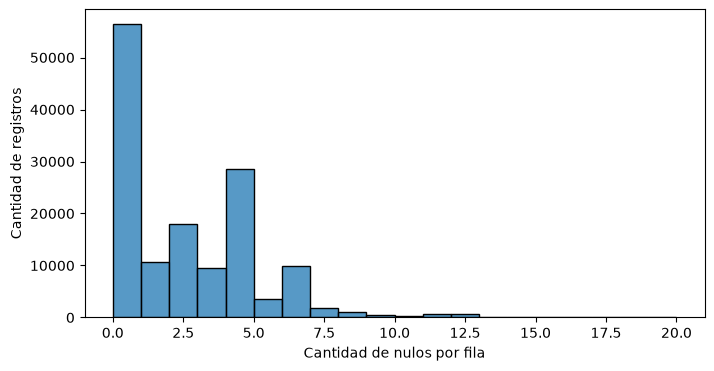


Cantidad de registros por cantidad de nulos por fila:


0     56412
1     10764
2     18023
3      9607
4     28531
5      3639
6      9934
7      1801
8       964
9       393
10      290
11      679
12      757
13      106
14       39
15       26
16       27
17       91
18       49
19       16
20        5
Name: count, dtype: int64

In [ ]:
nulos_fila = df.isnull().sum(axis=1)

plt.figure(figsize=(8,4))

sns.histplot(nulos_fila, bins=20)

plt.xlabel("Cantidad de nulos por fila")
plt.ylabel("Cantidad de registros")
plt.show()

print("\nCantidad de registros por cantidad de nulos por fila:")
nulos_fila.value_counts().sort_index()

#### Promedio de nulos por cuidad

In [ ]:
(df.groupby("Location").apply(lambda x: x.isnull().mean()*100))

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
Location,,,,,,,,,,,,,,,,,,,,,
Adelaide,0.0,0.064725,0.064725,2.265372,46.634304,45.048544,0.744337,0.744337,8.381877,0.485437,...,0.161812,0.258900,0.226537,100.000000,100.000000,0.161812,0.129450,2.265372,0.0,0.0
Albany,0.0,1.956882,1.061360,0.663350,9.253731,16.749585,100.000000,100.000000,8.092869,25.406302,...,23.184080,0.829187,0.796020,1.160862,23.018242,1.194030,23.051410,0.663350,0.0,0.0
Albury,0.0,0.199336,0.033223,0.664452,100.000000,100.000000,0.332226,0.332226,17.176080,1.362126,...,0.132890,0.000000,0.132890,57.441860,53.023256,0.132890,0.132890,0.664452,0.0,0.0
AliceSprings,0.0,0.032992,0.032992,0.197954,6.961399,16.859122,1.649621,1.649621,7.588255,0.131970,...,0.164962,0.032992,0.098977,10.953481,11.811283,0.000000,0.065985,0.197954,0.0,0.0
BadgerysCreek,0.0,0.409976,0.102494,1.742398,100.000000,100.000000,0.546635,0.546635,13.460881,2.049880,...,1.059105,4.885548,5.056372,100.000000,100.000000,0.546635,0.683293,1.742398,0.0,0.0
Ballarat,0.0,0.033036,0.033036,0.363396,100.000000,100.000000,0.792864,0.792864,3.006277,0.528576,...,0.198216,0.792864,0.792864,17.971589,34.390486,0.396432,0.165180,0.363396,0.0,0.0
Bendigo,0.0,0.032971,0.032971,0.131883,60.929773,100.000000,1.186944,1.153973,8.011869,1.384768,...,0.032971,0.461589,0.296736,31.783712,25.288493,0.065941,0.032971,0.131883,0.0,0.0
Brisbane,0.0,0.189873,0.126582,0.917722,0.601266,1.518987,0.474684,0.474684,2.183544,0.854430,...,0.284810,0.000000,0.063291,0.031646,0.063291,0.063291,0.284810,0.917722,0.0,0.0
Cairns,0.0,0.033478,0.000000,0.803482,11.382658,14.228323,0.602611,0.569133,1.406093,0.133914,...,0.000000,0.000000,0.000000,6.193505,6.896552,0.000000,0.000000,0.803482,0.0,0.0


**Nota para el grupo: hay que decidir que hacer con la variable RainFallTomorrow, probablemente eliminarla, está ligada al target sin ser target. Hay que afinar el analisis de nulos para despues decidir que hacer con esos porcentajes tan altos y los patrones que se forman con cada cuidad.**